## MNIST_CNN

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical

In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training data shape:", x_train.shape)
print("Training labels shape:", y_train.shape)
print("Test data shape:", x_test.shape)
print("Test labels shape:", y_test.shape)


Training data shape: (60000, 28, 28)
Training labels shape: (60000,)
Test data shape: (10000, 28, 28)
Test labels shape: (10000,)


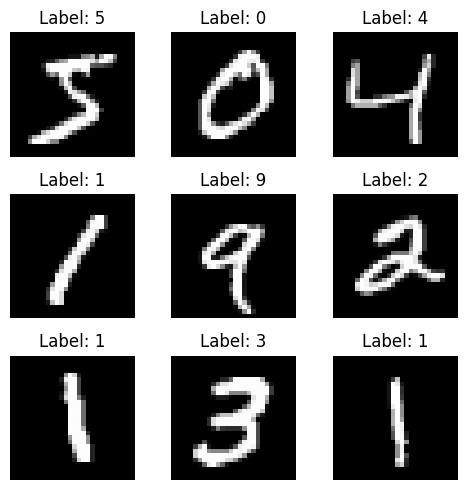

In [3]:
plt.figure(figsize=(5,5))
for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()


In [4]:
x_train = x_train / 255.0
x_test = x_test / 255.0


In [5]:
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

print("New training shape:", x_train.shape)
print("New test shape:", x_test.shape)


New training shape: (60000, 28, 28, 1)
New test shape: (10000, 28, 28, 1)


In [6]:
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

print("Encoded label shape:", y_train.shape)


Encoded label shape: (60000, 10)


In [7]:
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
    MaxPooling2D((2,2)),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])


In [8]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


In [9]:
model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d (MaxPooling2  (None, 13, 13, 32)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 11, 11, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 5, 5, 64)          0         
 g2D)                                                            
                                                                 
 flatten (Flatten)           (None, 1600)              0         
                                                                 
 dense (Dense)               (None, 128)               2

In [10]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)


Epoch 1/10


375/375 [==============================] - 6s 14ms/step - loss: 0.3615 - accuracy: 0.8877 - val_loss: 0.0788 - val_accuracy: 0.9768
Epoch 2/10
375/375 [==============================] - 5s 13ms/step - loss: 0.1111 - accuracy: 0.9661 - val_loss: 0.0567 - val_accuracy: 0.9843
Epoch 3/10
375/375 [==============================] - 5s 13ms/step - loss: 0.0819 - accuracy: 0.9759 - val_loss: 0.0454 - val_accuracy: 0.9881
Epoch 4/10
375/375 [==============================] - 5s 13ms/step - loss: 0.0676 - accuracy: 0.9797 - val_loss: 0.0426 - val_accuracy: 0.9868
Epoch 5/10
375/375 [==============================] - 5s 14ms/step - loss: 0.0566 - accuracy: 0.9831 - val_loss: 0.0360 - val_accuracy: 0.9900
Epoch 6/10
375/375 [==============================] - 5s 13ms/step - loss: 0.0492 - accuracy: 0.9852 - val_loss: 0.0465 - val_accuracy: 0.9873
Epoch 7/10
375/375 [==============================] - 5s 13ms/step - loss: 0.0446 - accuracy: 0.9868 - val_loss: 0.0355 - val_accuracy: 0.99

In [11]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)
print("Test Accuracy:", test_accuracy)


313/313 [==============================] - 1s 4ms/step - loss: 0.0262 - accuracy: 0.9910
Test Accuracy: 0.9909999966621399


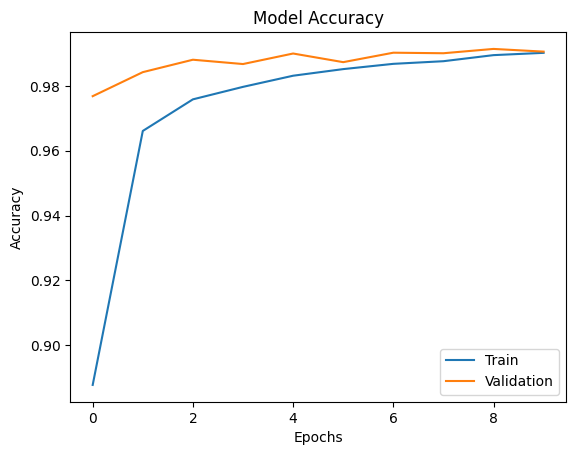

In [12]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])
plt.show()


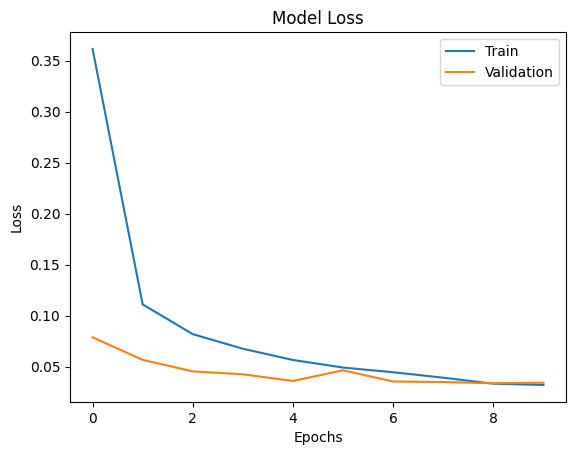

In [13]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'])
plt.show()


In [14]:
model.save("../models/mnist_cnn_model.keras")


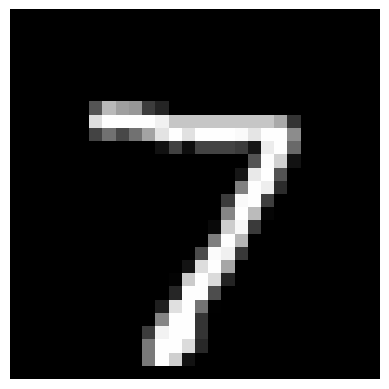

1/1 [==============================] - 0s 121ms/step
Predicted Digit: 7


In [15]:
index = 0

plt.imshow(x_test[index].reshape(28,28), cmap='gray')
plt.axis('off')
plt.show()

prediction = model.predict(x_test[index].reshape(1,28,28,1))
print("Predicted Digit:", np.argmax(prediction))


### Custom Prediction

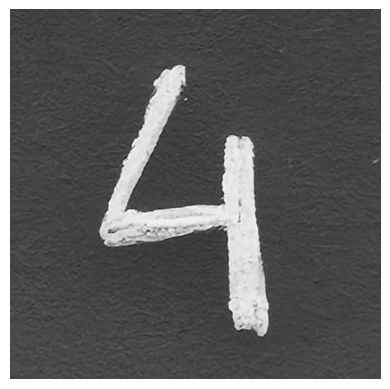

In [16]:
import cv2

img = cv2.imread("../sample_inputs/digit.png", cv2.IMREAD_GRAYSCALE)
img = 1 - img
plt.imshow(img, cmap='gray')
plt.axis('off')
plt.show()


In [17]:
img = cv2.resize(img, (28,28))
img = img / 255.0
img = img.reshape(1,28,28,1)


In [18]:
pred = model.predict(img)
print("Predicted Digit:", np.argmax(pred))


1/1 [==============================] - 0s 26ms/step
Predicted Digit: 4


## Evaluation

In [19]:
y_pred = model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)

313/313 [==============================] - 1s 3ms/step


In [20]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_true, y_pred_classes)


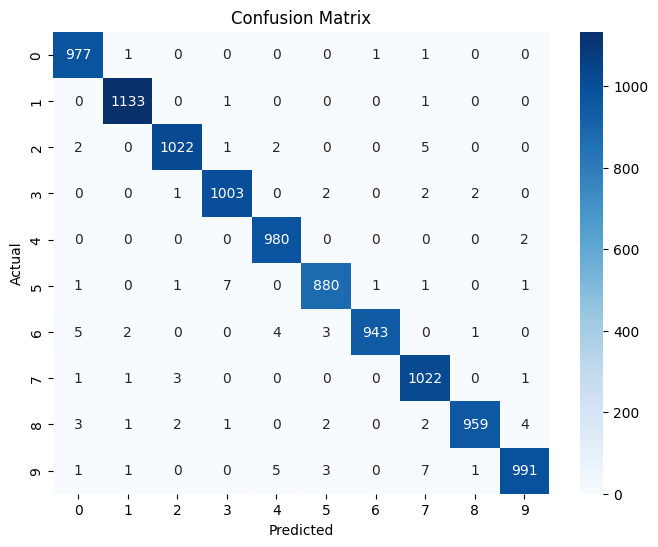

In [21]:
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()


In [22]:
from sklearn.metrics import classification_report
print(classification_report(y_true, y_pred_classes))


              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       0.99      1.00      1.00      1135
           2       0.99      0.99      0.99      1032
           3       0.99      0.99      0.99      1010
           4       0.99      1.00      0.99       982
           5       0.99      0.99      0.99       892
           6       1.00      0.98      0.99       958
           7       0.98      0.99      0.99      1028
           8       1.00      0.98      0.99       974
           9       0.99      0.98      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



In [23]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [24]:
history = model.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=128,
    validation_split=0.2,
    callbacks=[early_stop]
)


Epoch 1/20
375/375 [==============================] - 5s 14ms/step - loss: 0.0278 - accuracy: 0.9914 - val_loss: 0.0317 - val_accuracy: 0.9922
Epoch 2/20
375/375 [==============================] - 5s 13ms/step - loss: 0.0263 - accuracy: 0.9916 - val_loss: 0.0338 - val_accuracy: 0.9909
Epoch 3/20
375/375 [==============================] - 5s 13ms/step - loss: 0.0238 - accuracy: 0.9922 - val_loss: 0.0405 - val_accuracy: 0.9910
Epoch 4/20
375/375 [==============================] - 5s 13ms/step - loss: 0.0218 - accuracy: 0.9928 - val_loss: 0.0371 - val_accuracy: 0.9900


In [25]:
y_pred = model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)

print(classification_report(y_true, y_pred_classes))

313/313 [==============================] - 1s 3ms/step
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      1.00      1.00      1135
           2       0.99      0.99      0.99      1032
           3       0.99      0.99      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      0.98      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.98      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



### Custom Prediction

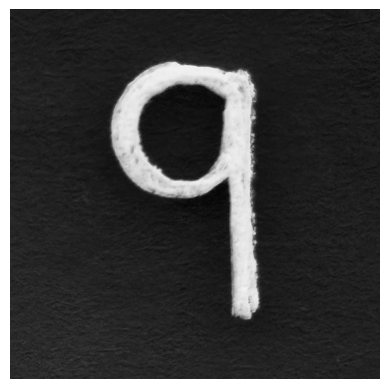

In [27]:
import cv2

img = cv2.imread("../sample_inputs/nine.png", cv2.IMREAD_GRAYSCALE)
img = 1 - img
plt.imshow(img, cmap='gray')
plt.axis('off')
plt.show()


In [28]:
img = cv2.resize(img, (28,28))
img = img / 255.0
img = img.reshape(1,28,28,1)

In [29]:
pred = model.predict(img)
print("Predicted Digit:", np.argmax(pred))

1/1 [==============================] - 0s 26ms/step
Predicted Digit: 9


In [30]:
model.save("../models/mnist_cnn_final.keras")

## EMNIST_TFDS

In [31]:
import numpy as np
import tensorflow as tf
import cv2

print("NumPy:", np.__version__)
print("TensorFlow:", tf.__version__)
print("OpenCV:", cv2.__version__)

NumPy: 1.26.4
TensorFlow: 2.15.0
OpenCV: 4.8.1


In [32]:
# %pip install emnist

# from emnist import extract_training_samples, extract_test_samples

# x_train, y_train = extract_training_samples('letters')
# x_test, y_test = extract_test_samples('letters')

# print(x_train.shape, y_train.shape)


In [33]:
# %pip install tensorflow-datasets

import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical

```Load EMNIST Letters using TFDS```

In [34]:
(ds_train, ds_test), info = tfds.load(
    'emnist/letters',
    split=['train', 'test'],
    as_supervised=True,
    with_info=True
)

Convert TFDS → NumPy Arrays

In [35]:
x_train = np.array([x.numpy() for x, y in ds_train])
y_train = np.array([y.numpy() for x, y in ds_train])

x_test = np.array([x.numpy() for x, y in ds_test])
y_test = np.array([y.numpy() for x, y in ds_test])

print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)

(88800, 28, 28, 1) (88800,)
(14800, 28, 28, 1) (14800,)


In [36]:
y_train = y_train- 1
y_test = y_test - 1

In [37]:
x_train = np.rot90(x_train, k=1, axes=(1,2))
x_test = np.rot90(x_test, k=1, axes=(1,2))

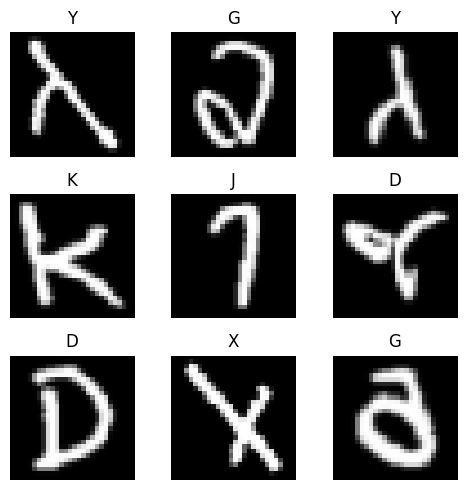

In [38]:
import string
letters = string.ascii_uppercase

plt.figure(figsize=(5,5))
for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(letters[y_train[i]])
    plt.axis('off')
plt.tight_layout()
plt.show()


In [39]:
x_train = x_train / 255.0
x_test = x_test / 255.0

In [40]:
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

print(x_train.shape)

(88800, 28, 28, 1)


In [41]:
y_train = to_categorical(y_train, 26)
y_test = to_categorical(y_test, 26)

print(y_train.shape)

(88800, 26)


In [42]:
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
    MaxPooling2D((2,2)),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(26, activation='softmax')
])

In [43]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [44]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_2 (Conv2D)           (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d_2 (MaxPoolin  (None, 13, 13, 32)        0         
 g2D)                                                            
                                                                 
 conv2d_3 (Conv2D)           (None, 11, 11, 64)        18496     
                                                                 
 max_pooling2d_3 (MaxPoolin  (None, 5, 5, 64)          0         
 g2D)                                                            
                                                                 
 flatten_1 (Flatten)         (None, 1600)              0         
                                                                 
 dense_2 (Dense)             (None, 128)              

In [45]:
history = model.fit(
    x_train,
    y_train,
    epochs=15,
    batch_size=128,
    validation_split=0.2
)

Epoch 1/15
555/555 [==============================] - 9s 14ms/step - loss: 1.0836 - accuracy: 0.6714 - val_loss: 0.3919 - val_accuracy: 0.8739
Epoch 2/15
555/555 [==============================] - 8s 14ms/step - loss: 0.5470 - accuracy: 0.8269 - val_loss: 0.3022 - val_accuracy: 0.9014
Epoch 3/15
555/555 [==============================] - 7s 13ms/step - loss: 0.4482 - accuracy: 0.8587 - val_loss: 0.2731 - val_accuracy: 0.9093
Epoch 4/15
555/555 [==============================] - 8s 14ms/step - loss: 0.3917 - accuracy: 0.8763 - val_loss: 0.2502 - val_accuracy: 0.9196
Epoch 5/15
555/555 [==============================] - 7s 13ms/step - loss: 0.3509 - accuracy: 0.8870 - val_loss: 0.2409 - val_accuracy: 0.9211
Epoch 6/15
555/555 [==============================] - 7s 13ms/step - loss: 0.3240 - accuracy: 0.8945 - val_loss: 0.2238 - val_accuracy: 0.9269
Epoch 7/15
555/555 [==============================] - 7s 13ms/step - loss: 0.3001 - accuracy: 0.9006 - val_loss: 0.2197 - val_accuracy: 0.9283

In [46]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print("Test Accuracy:", test_acc)

463/463 [==============================] - 1s 3ms/step - loss: 0.2384 - accuracy: 0.9244
Test Accuracy: 0.9243918657302856


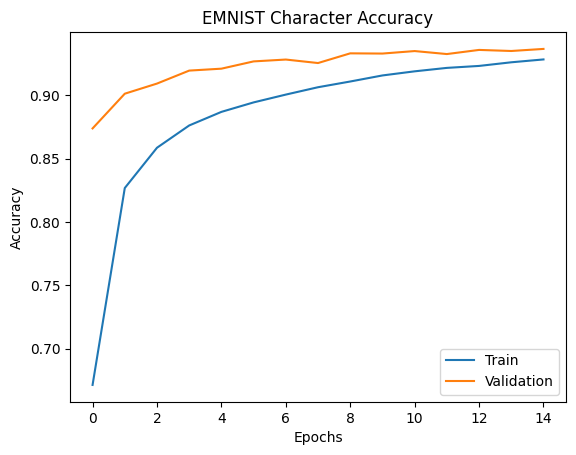

In [48]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('EMNIST Character Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])
plt.show()

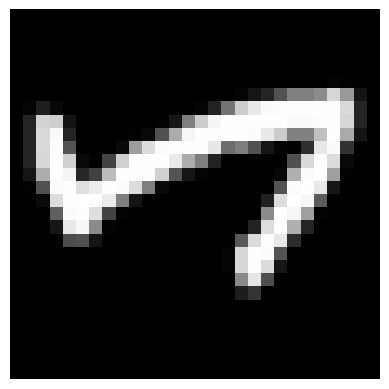

1/1 [==============================] - 0s 51ms/step
Predicted: N
Actual: N


In [49]:
index = 100

img = x_test[index]
plt.imshow(img.reshape(28,28), cmap='gray')
plt.axis('off')
plt.show()

pred = model.predict(img.reshape(1,28,28,1))
print("Predicted:", letters[np.argmax(pred)])
print("Actual:", letters[np.argmax(y_test[index])])

In [50]:
model.save("../models/emnist_character_cnn_tfds.keras")

## Improvement_Evaluation

In [51]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import confusion_matrix, classification_report

In [52]:
print("Training samples:", x_train.shape)
print("Test samples:", x_test.shape)

Training samples: (88800, 28, 28, 1)
Test samples: (14800, 28, 28, 1)


In [53]:
datagen = ImageDataGenerator(
    rotation_range=10,
    zoom_range=0.1,
    width_shift_range=0.1,
    height_shift_range=0.1
)

datagen.fit(x_train)


In [54]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [55]:
history = model.fit(
    datagen.flow(x_train, y_train, batch_size=128),
    epochs=25,
    validation_data=(x_test, y_test),
    callbacks=[early_stop]
)

Epoch 1/25
694/694 [==============================] - 34s 48ms/step - loss: 0.5011 - accuracy: 0.8425 - val_loss: 0.2254 - val_accuracy: 0.9224
Epoch 2/25
694/694 [==============================] - 26s 37ms/step - loss: 0.4332 - accuracy: 0.8634 - val_loss: 0.2268 - val_accuracy: 0.9216
Epoch 3/25
694/694 [==============================] - 34s 49ms/step - loss: 0.4034 - accuracy: 0.8718 - val_loss: 0.2201 - val_accuracy: 0.9255
Epoch 4/25
694/694 [==============================] - 34s 49ms/step - loss: 0.3797 - accuracy: 0.8787 - val_loss: 0.2290 - val_accuracy: 0.9195
Epoch 5/25
694/694 [==============================] - 34s 49ms/step - loss: 0.3681 - accuracy: 0.8812 - val_loss: 0.2325 - val_accuracy: 0.9197
Epoch 6/25
694/694 [==============================] - 33s 48ms/step - loss: 0.3539 - accuracy: 0.8858 - val_loss: 0.2210 - val_accuracy: 0.9255


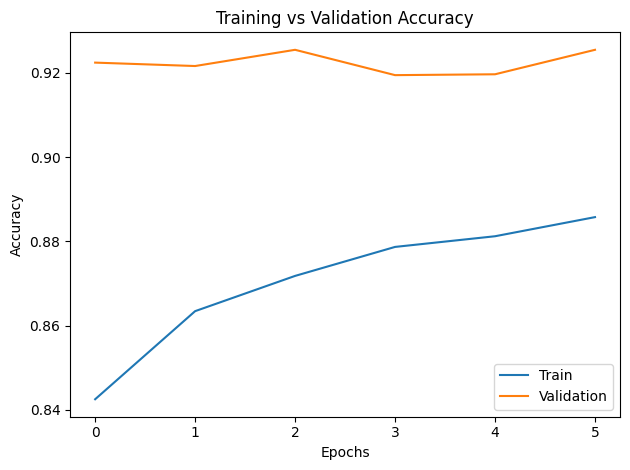

In [56]:
plt.figure()
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend(['Train', 'Validation'])
plt.tight_layout()
plt.savefig("../output/training_accuracy.png", dpi=300)
plt.show()

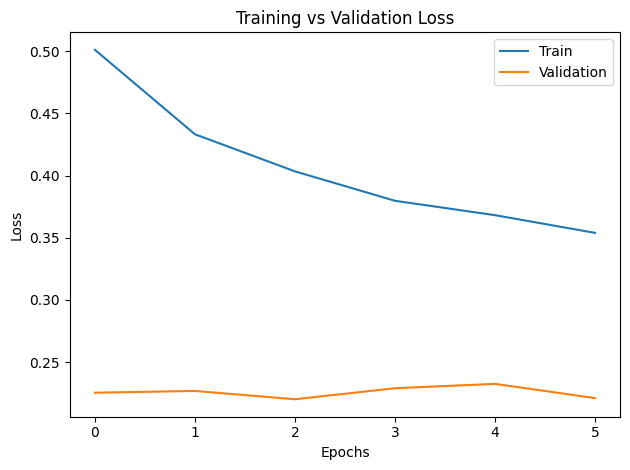

In [57]:
plt.figure()
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend(['Train', 'Validation'])
plt.tight_layout()
plt.savefig("../output/training_loss.png", dpi=300)
plt.show()

In [58]:
y_pred = model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)

463/463 [==============================] - 1s 3ms/step


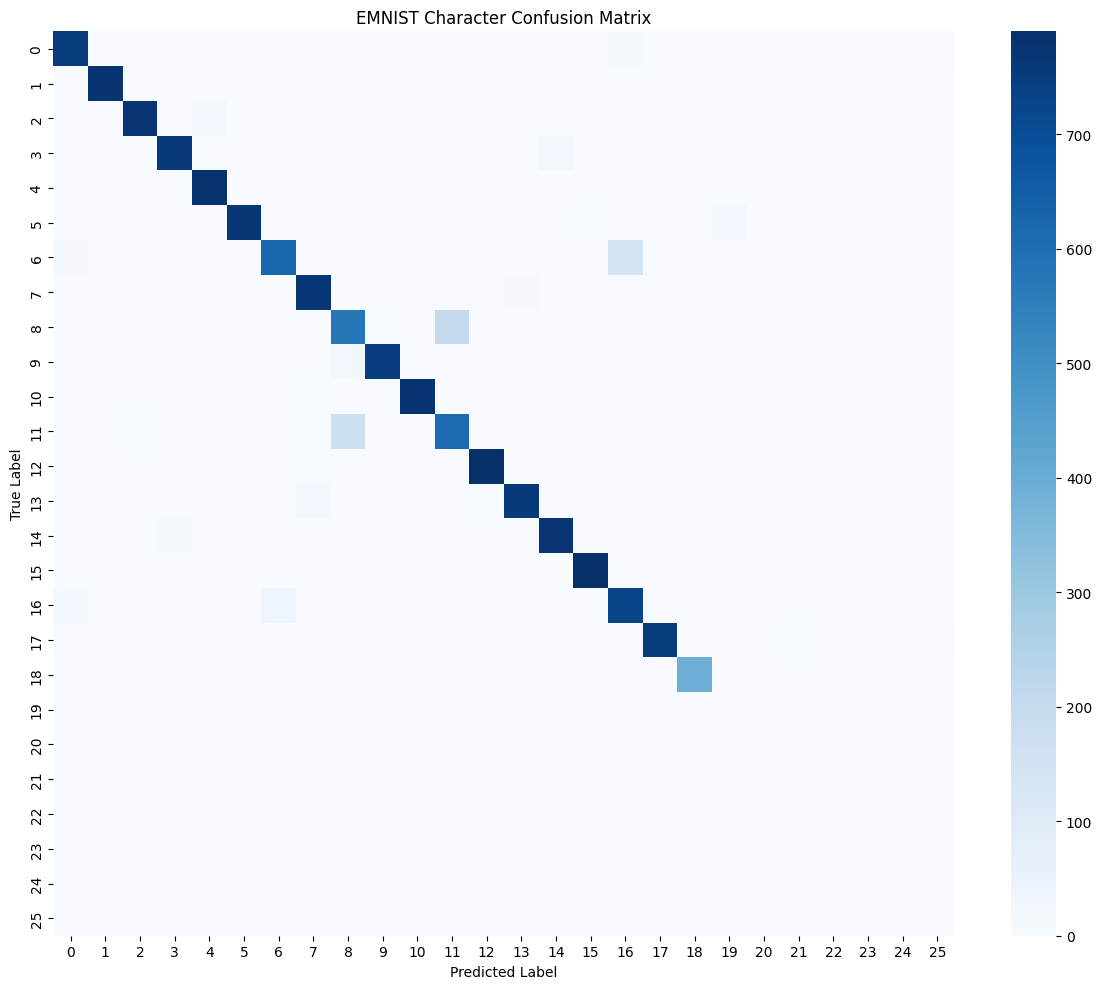

In [62]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_true, y_pred_classes)

plt.figure(figsize=(12,10))
sns.heatmap(cm, cmap="Blues", cbar=True)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("EMNIST Character Confusion Matrix")
plt.tight_layout()
plt.savefig("../output/confusion_matrix.png", dpi=300)
plt.show()

In [63]:
print(classification_report(y_true, y_pred_classes))

              precision    recall  f1-score   support

           0       0.94      0.94      0.94       800
           1       0.97      0.97      0.97       800
           2       0.97      0.96      0.97       800
           3       0.96      0.95      0.95       800
           4       0.97      0.98      0.97       800
           5       0.98      0.96      0.97       800
           6       0.93      0.78      0.85       800
           7       0.94      0.96      0.95       800
           8       0.75      0.72      0.73       800
           9       0.98      0.94      0.96       800
          10       0.98      0.97      0.98       800
          11       0.74      0.76      0.75       800
          12       0.99      0.98      0.99       800
          13       0.97      0.95      0.96       800
          14       0.96      0.96      0.96       800
          15       0.98      0.99      0.98       800
          16       0.81      0.91      0.86       800
          17       0.98    

D:\SoftWares\Anaconda\envs\hcr\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
D:\SoftWares\Anaconda\envs\hcr\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
D:\SoftWares\Anaconda\envs\hcr\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


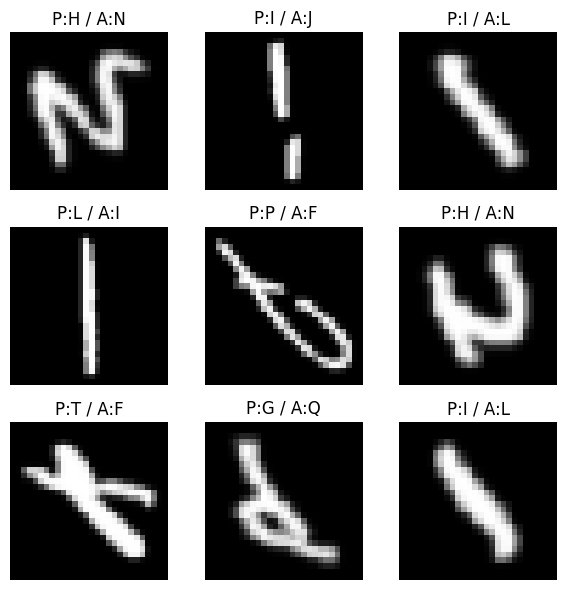

In [64]:
import string
letters = string.ascii_uppercase

wrong = np.where(y_pred_classes != y_true)[0]

plt.figure(figsize=(6,6))
for i, idx in enumerate(wrong[:9]):
    plt.subplot(3,3,i+1)
    plt.imshow(x_test[idx].reshape(28,28), cmap='gray')
    plt.title(f"P:{letters[y_pred_classes[idx]]} / A:{letters[y_true[idx]]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

In [65]:
model.save("../models/emnist_character_cnn_tfds_final.keras")

## Final_Demo

In [66]:
import numpy as np
import matplotlib.pyplot as plt
import string
import cv2

import tensorflow as tf
from tensorflow.keras.models import load_model

In [67]:
model = load_model("../models/emnist_character_cnn_tfds_final.keras")
print("Model loaded successfully")

Model loaded successfully


In [68]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print("Final Test Accuracy:", test_acc)

463/463 [==============================] - 2s 3ms/step - loss: 0.2201 - accuracy: 0.9255
Final Test Accuracy: 0.9254729747772217


1/1 [==============================] - 0s 20ms/step


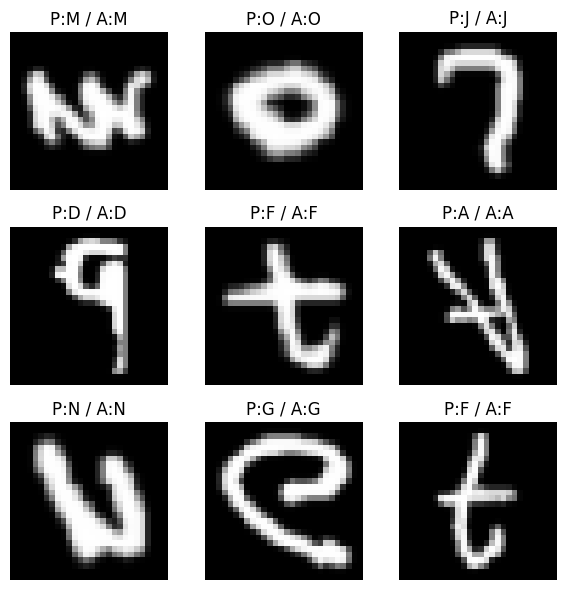

In [69]:
letters = string.ascii_uppercase

plt.figure(figsize=(6,6))
for i in range(9):
    idx = np.random.randint(0, len(x_test))
    img = x_test[idx]
    pred = model.predict(img.reshape(1,28,28,1))
    
    plt.subplot(3,3,i+1)
    plt.imshow(img.reshape(28,28), cmap='gray')
    plt.title(f"P:{letters[np.argmax(pred)]} / A:{letters[np.argmax(y_test[idx])]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

### Custom Input

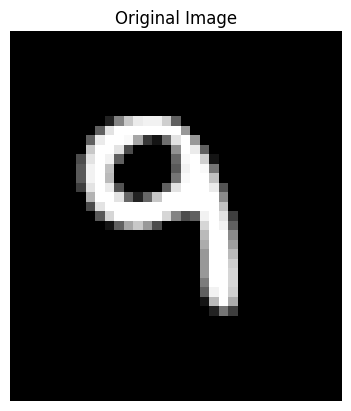

In [82]:
img = cv2.imread("../sample_inputs/char.png", cv2.IMREAD_GRAYSCALE)

plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis('off')
plt.show()

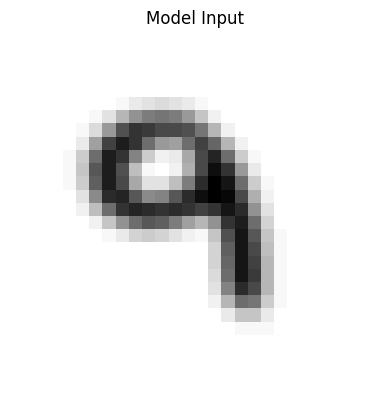

In [83]:
img = cv2.resize(img, (28,28))

# invert if needed
img = 255 - img

# smooth strokes
img = cv2.GaussianBlur(img, (3,3), 0)

# normalize
img = img / 255.0

# reshape
img = img.reshape(1,28,28,1)

plt.imshow(img.reshape(28,28), cmap='gray')
plt.title("Model Input")
plt.axis('off')
plt.show()

In [84]:
pred = model.predict(img)
print("Predicted Character:", letters[np.argmax(pred)])

1/1 [==============================] - 0s 26ms/step
Predicted Character: L


In [85]:
result = letters[np.argmax(pred)]
with open("../output/prediction.txt", "a") as f:
    f.write(f"Predicted Character: {result}\n")

print("Prediction saved to prediction.txt")

Prediction saved to prediction.txt


## Project Summary

In [86]:
print("Project Summary")
print("----------------")
print("Dataset: EMNIST Letters (A–Z)")
print("Model: CNN")
print("Input size: 28x28 grayscale")
print("Output classes: 26")
print("Final Test Accuracy:", round(test_acc*100, 2), "%")

Project Summary
----------------
Dataset: EMNIST Letters (A–Z)
Model: CNN
Input size: 28x28 grayscale
Output classes: 26
Final Test Accuracy: 92.55 %
